In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mysql.connector

In [2]:
%pip install mysql-connector-python

Note: you may need to restart the kernel to use updated packages.


In [3]:
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root",
    database="airline"
)

print("MySQL connected successfully!")

MySQL connected successfully!


In [4]:
flights = pd.read_sql("SELECT * FROM flights", conn)
print(flights.head())
passengers = pd.read_sql("SELECT * FROM passengers", conn)
print(passengers.head())

   flight_id  airline_id flight_number     source destination flight_date  \
0          1           3         VI159      Delhi      Mumbai  2026-04-12   
1          2           5         GO192  Bangalore   Hyderabad  2026-01-10   
2          3           5         GO506  Hyderabad       Delhi  2026-01-16   
3          4           1         IN731    Chennai      Mumbai  2026-03-21   
4          5           4         SP418     Mumbai     Kolkata  2026-05-03   

   departure_time    arrival_time  scheduled_duration  actual_duration  \
0 0 days 07:00:00 0 days 08:39:00                  99               99   
1 0 days 08:45:00 0 days 11:47:00                 182              182   
2 0 days 09:15:00 0 days 10:45:00                  90                0   
3 0 days 10:30:00 0 days 12:22:00                 112              112   
4 0 days 18:00:00 0 days 20:25:00                 145              178   

   delay_minutes     status  ticket_price  
0              0    On Time       11750.0  
1   

C:\Users\acer\AppData\Local\Temp\ipykernel_16928\4121439978.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  flights = pd.read_sql("SELECT * FROM flights", conn)
C:\Users\acer\AppData\Local\Temp\ipykernel_16928\4121439978.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  passengers = pd.read_sql("SELECT * FROM passengers", conn)


C:\Users\acer\AppData\Local\Temp\ipykernel_16928\1338096530.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql("SELECT flight_id, count(*) AS passenger_count FROM passengers GROUP BY flight_id;", conn)


C:\Users\acer\AppData\Local\Temp\ipykernel_16928\1338096530.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='flight_id', y='passenger_count', palette='viridis')


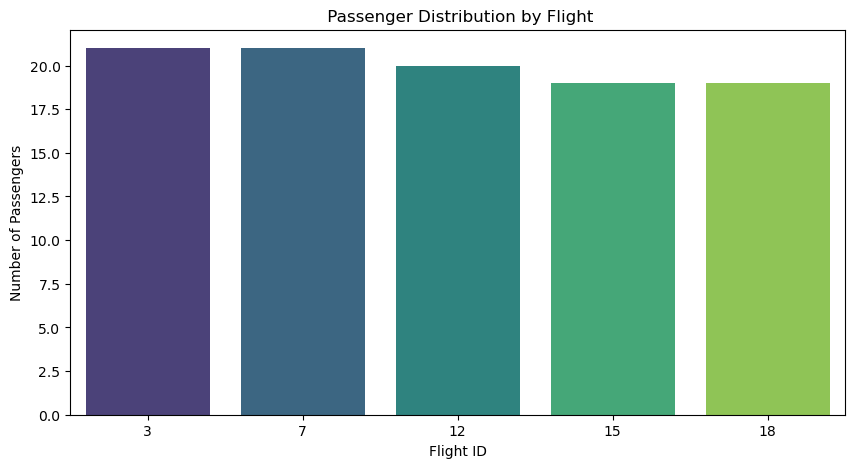

In [5]:
df=pd.read_sql("SELECT flight_id, count(*) AS passenger_count FROM passengers GROUP BY flight_id;", conn)

plt.figure(figsize=(10,5))
sns.barplot(data=df, x='flight_id', y='passenger_count', palette='viridis')
plt.title(" Passenger Distribution by Flight")
plt.xlabel("Flight ID")
plt.ylabel("Number of Passengers")
plt.show()

C:\Users\acer\AppData\Local\Temp\ipykernel_16928\1582628905.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql("SELECT ticket_class, count(*) AS passenger_count FROM passengers GROUP BY ticket_class;", conn)


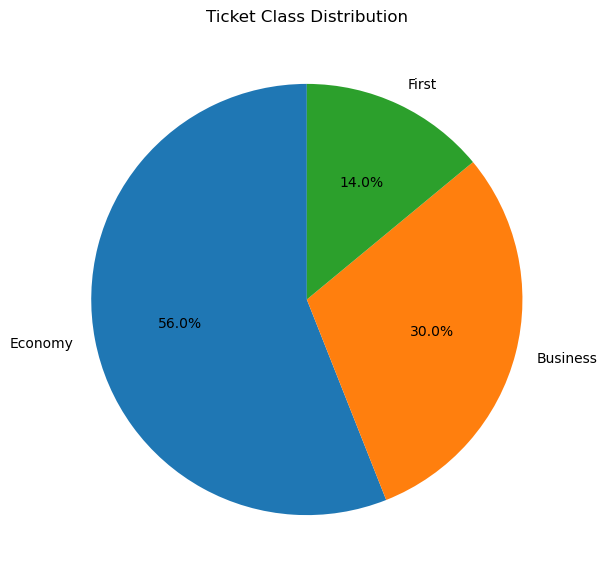

In [6]:
df=pd.read_sql("SELECT ticket_class, count(*) AS passenger_count FROM passengers GROUP BY ticket_class;", conn)

plt.figure(figsize=(7,7))

plt.pie(
    df['passenger_count'],
    labels=df['ticket_class'],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Ticket Class Distribution")
plt.show()

C:\Users\acer\AppData\Local\Temp\ipykernel_16928\247436489.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql("SELECT ticket_class, AVG(ticket_price) AS ticket_price FROM passengers GROUP BY ticket_class;", conn)
C:\Users\acer\AppData\Local\Temp\ipykernel_16928\247436489.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df,x="ticket_price",y="ticket_class", palette="viridis")


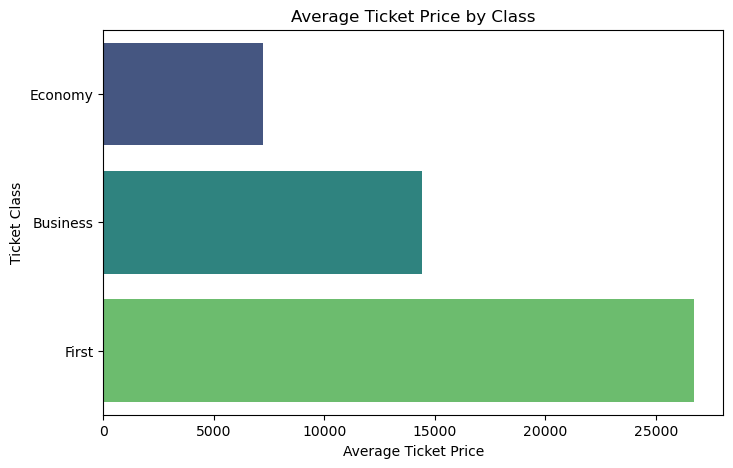

In [7]:
df=pd.read_sql("SELECT ticket_class, AVG(ticket_price) AS ticket_price FROM passengers GROUP BY ticket_class;", conn)
plt.figure(figsize=(8,5))
sns.barplot(data=df,x="ticket_price",y="ticket_class", palette="viridis")
plt.title("Average Ticket Price by Class")
plt.xlabel("Average Ticket Price")
plt.ylabel("Ticket Class")
plt.show()

C:\Users\acer\AppData\Local\Temp\ipykernel_16928\1026623673.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql("SELECT f.airline_id,SUM(p.ticket_price) as Total_revenue FROM flights f inner join passengers p on f.flight_id=p.flight_id group by f.airline_id;", conn)
C:\Users\acer\AppData\Local\Temp\ipykernel_16928\1026623673.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df,x="airline_id",y="Total_revenue",palette="viridis")


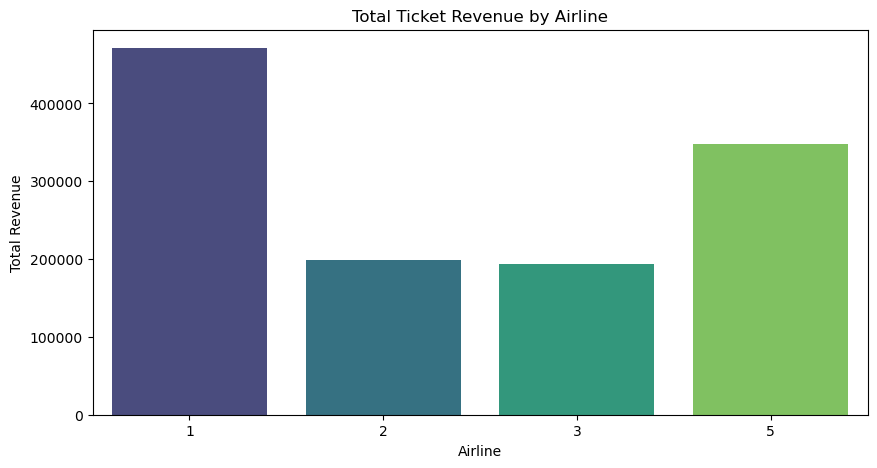

In [8]:
df=pd.read_sql("SELECT f.airline_id,SUM(p.ticket_price) as Total_revenue FROM flights f inner join passengers p on f.flight_id=p.flight_id group by f.airline_id;", conn)
plt.figure(figsize=(10,5))
sns.barplot(data=df,x="airline_id",y="Total_revenue",palette="viridis")
plt.title("Total Ticket Revenue by Airline")
plt.xlabel("Airline")
plt.ylabel("Total Revenue")
plt.show()

C:\Users\acer\AppData\Local\Temp\ipykernel_16928\1451939133.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df=pd.read_sql("SELECT booking_status, count(*) AS booking_count FROM passengers GROUP BY booking_status;", conn)


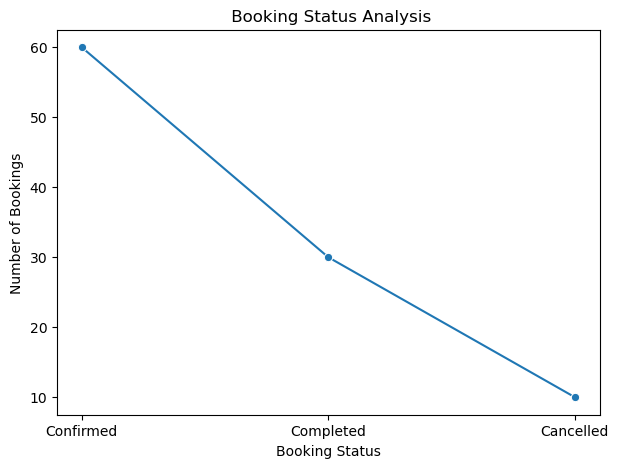

In [9]:
df=pd.read_sql("SELECT booking_status, count(*) AS booking_count FROM passengers GROUP BY booking_status;", conn)
plt.figure(figsize=(7,5))
sns.lineplot(data=df,x="booking_status",y="booking_count",marker="o")
plt.title(" Booking Status Analysis")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")

plt.show()

C:\Users\acer\AppData\Local\Temp\ipykernel_16928\2142677460.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df1 = pd.read_sql(query1, conn)


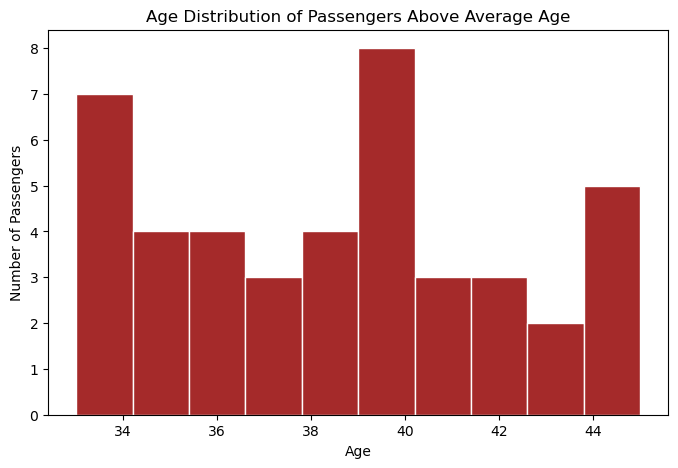

In [10]:
query1 = "SELECT passenger_name, age, gender, nationality FROM passengers WHERE age > (SELECT AVG(age) FROM passengers)"
df1 = pd.read_sql(query1, conn)
df1.head()
plt.figure(figsize=(8,5))
plt.hist(df1["age"],bins=10,edgecolor="white",color="brown")
plt.title("Age Distribution of Passengers Above Average Age")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()

C:\Users\acer\AppData\Local\Temp\ipykernel_16928\1198908576.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df2 = pd.read_sql(query2, conn)
C:\Users\acer\AppData\Local\Temp\ipykernel_16928\1198908576.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df2,y="flight_id",x="avg_ticket_price",color="green",palette="viridis")


   flight_id  avg_ticket_price
0          3      16590.476190
1          7      13357.142857


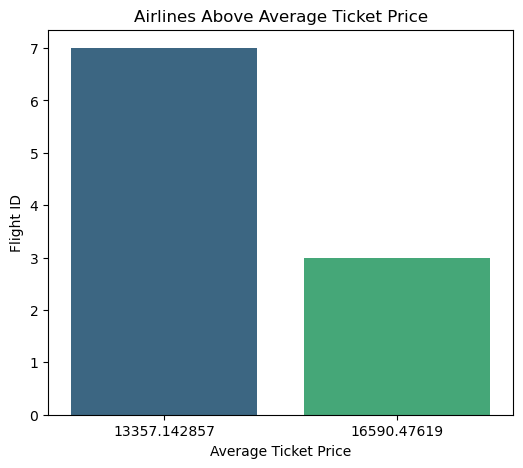

In [11]:
query2 = """SELECT flight_id, AVG(ticket_price) AS avg_ticket_price FROM passengers GROUP BY flight_id HAVING AVG(ticket_price) > (SELECT AVG(ticket_price)FROM passengers)
"""
df2 = pd.read_sql(query2, conn)
print(df2)
plt.figure(figsize=(6,5))
sns.barplot(data=df2,y="flight_id",x="avg_ticket_price",color="green",palette="viridis")
plt.title("Airlines Above Average Ticket Price")
plt.xlabel("Average Ticket Price")
plt.ylabel("Flight ID")
plt.show()

C:\Users\acer\AppData\Local\Temp\ipykernel_16928\2294105976.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df3 = pd.read_sql(query3, conn)


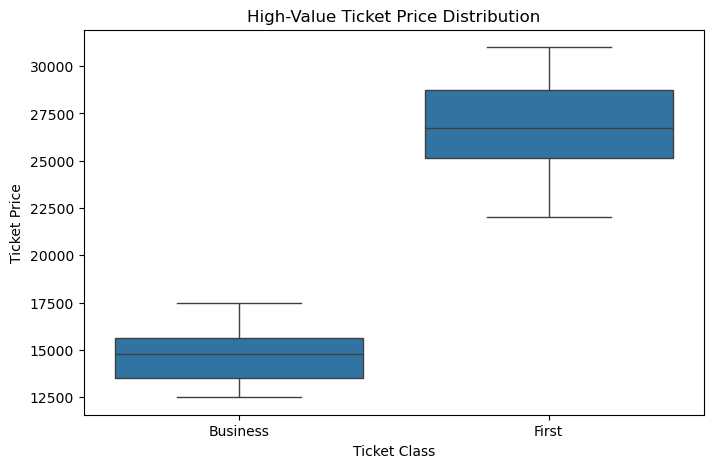

In [12]:
query3 = """SELECT passenger_name,ticket_class,ticket_price FROM passengers WHERE ticket_price > (SELECT AVG(ticket_price)FROM passengers)
"""
df3 = pd.read_sql(query3, conn)
df3.head()
plt.figure(figsize=(8,5))
sns.boxplot(data=df3,x="ticket_class",y="ticket_price")
plt.title("High-Value Ticket Price Distribution")
plt.xlabel("Ticket Class")
plt.ylabel("Ticket Price")

plt.show()

C:\Users\acer\AppData\Local\Temp\ipykernel_16928\866873016.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df4 = pd.read_sql(query4, conn)


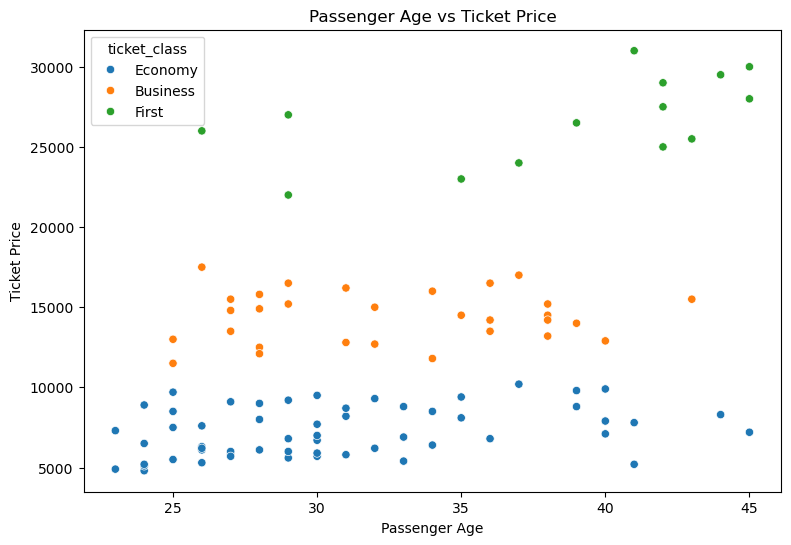

In [13]:
query4 = """
SELECT p.age,p.ticket_price,p.ticket_class,f.flight_number FROM passengers p JOIN flights f ON p.flight_id = f.flight_id """
df4 = pd.read_sql(query4, conn)
df4.head()
plt.figure(figsize=(9,6))
sns.scatterplot(data=df4,x="age",y="ticket_price",hue="ticket_class")
plt.title("Passenger Age vs Ticket Price")
plt.xlabel("Passenger Age")
plt.ylabel("Ticket Price")
plt.show()

C:\Users\acer\AppData\Local\Temp\ipykernel_16928\2709011071.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df5 = pd.read_sql(query5, conn)


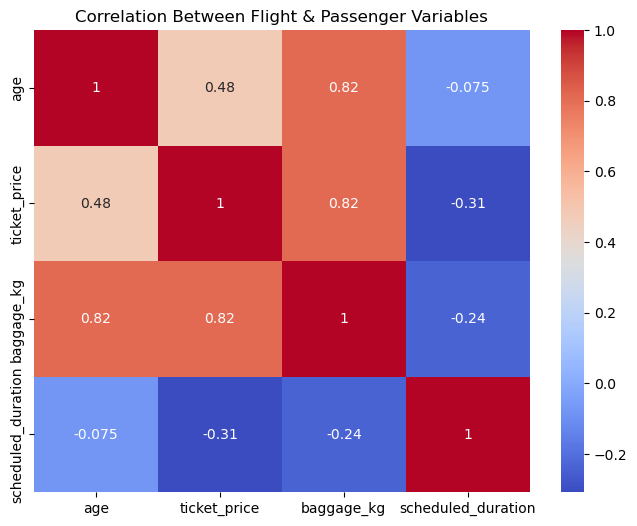

In [14]:
query5 = """
SELECT p.age,p.ticket_price,p.baggage_kg,f.scheduled_duration FROM passengers p JOIN flights f ON p.flight_id = f.flight_id """
df5 = pd.read_sql(query5, conn)
df5.head()
plt.figure(figsize=(8,6))
correlation = df5.corr(numeric_only=True)
sns.heatmap(correlation,annot=True,cmap="coolwarm")
plt.title("Correlation Between Flight & Passenger Variables")
plt.show()

C:\Users\acer\AppData\Local\Temp\ipykernel_16928\216630625.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df1 = pd.read_sql(query1, conn)
C:\Users\acer\AppData\Local\Temp\ipykernel_16928\216630625.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df1,x="total_passengers",y=df1["source"] + " → " + df1["destination"], ax=axes[0,0], palette="viridis")
C:\Users\acer\AppData\Local\Temp\ipykernel_16928\216630625.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df2 = pd.read_sql(query2, conn)
C:\Users\acer\AppData\Local\

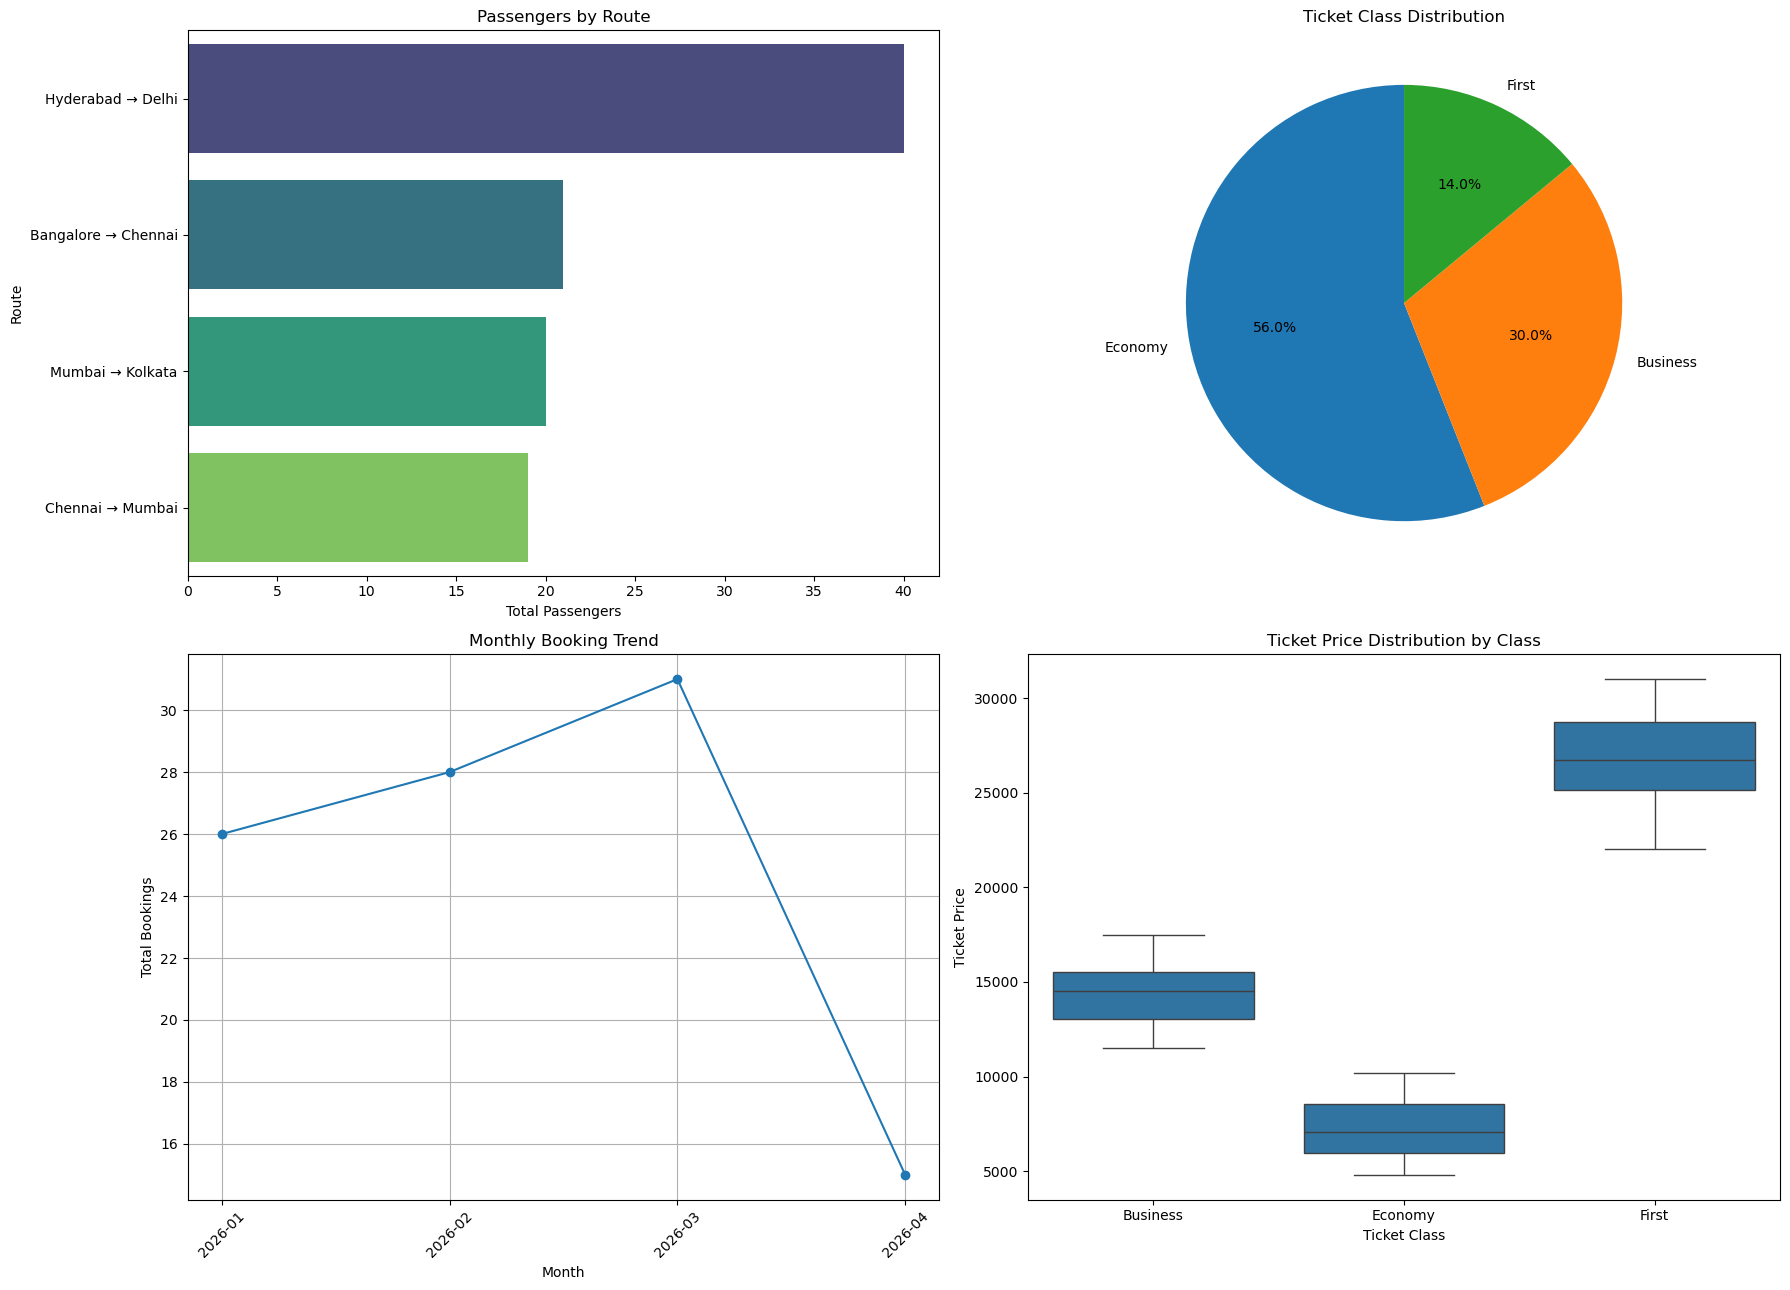

In [ ]:
                                    #Flight Booking & Passenger Analytics Dashboard

fig,axes=plt.subplots(2,2,figsize=(18,13))
query1 = """
SELECT f.source,f.destination,COUNT(p.passenger_id) AS total_passengers FROM passengers p JOIN flights f ON p.flight_id = f.flight_id GROUP BY f.source, f.destination ORDER BY total_passengers DESC;
"""
df1 = pd.read_sql(query1, conn)
sns.barplot(data=df1,x="total_passengers",y=df1["source"] + " → " + df1["destination"], ax=axes[0,0], palette="viridis")
axes[0,0].set_title("Passengers by Route")
axes[0,0].set_xlabel("Total Passengers")
axes[0,0].set_ylabel("Route")
plt.tight_layout()

query2 = """SELECT ticket_class,COUNT(*) AS total_passengers FROM passengers GROUP BY ticket_class;"""
df2 = pd.read_sql(query2, conn)
axes[0,1].pie(df2["total_passengers"],labels=df2["ticket_class"],autopct="%1.1f%%",startangle=90)
axes[0,1].set_title("Ticket Class Distribution")

query3 = """SELECT DATE_FORMAT(booking_date, '%Y-%m') AS booking_month,COUNT(*) AS total_bookings FROM passengers GROUP BY DATE_FORMAT(booking_date, '%Y-%m')ORDER BY booking_month;
"""
df3 = pd.read_sql(query3, conn)
axes[1,0].plot(df3["booking_month"],df3["total_bookings"],marker="o")
axes[1,0].set_title("Monthly Booking Trend")
axes[1,0].set_xlabel("Month")
axes[1,0].set_ylabel("Total Bookings")
axes[1,0].set_xticklabels(df3["booking_month"], rotation=45)
axes[1,0].grid(True)
plt.tight_layout()

query4 = """SELECT ticket_class,ticket_price FROM passengers ORDER BY ticket_class;"""
df4 = pd.read_sql(query4, conn)
sns.boxplot(data=df4,x="ticket_class",y="ticket_price", ax=axes[1,1])
axes[1,1].set_title("Ticket Price Distribution by Class")
axes[1,1].set_xlabel("Ticket Class")
axes[1,1].set_ylabel("Ticket Price")
plt.tight_layout()
plt.show()

C:\Users\acer\AppData\Local\Temp\ipykernel_16928\2441110632.py:5: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df1 = pd.read_sql(query1, conn)
C:\Users\acer\AppData\Local\Temp\ipykernel_16928\2441110632.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df2 = pd.read_sql(query2, conn)
C:\Users\acer\AppData\Local\Temp\ipykernel_16928\2441110632.py:19: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df3 = pd.read_sql(query3, conn)
C:\Users\acer\AppData\Local\Temp\ipykernel_16928\2441110632.py:28: UserWarning: pandas only sup

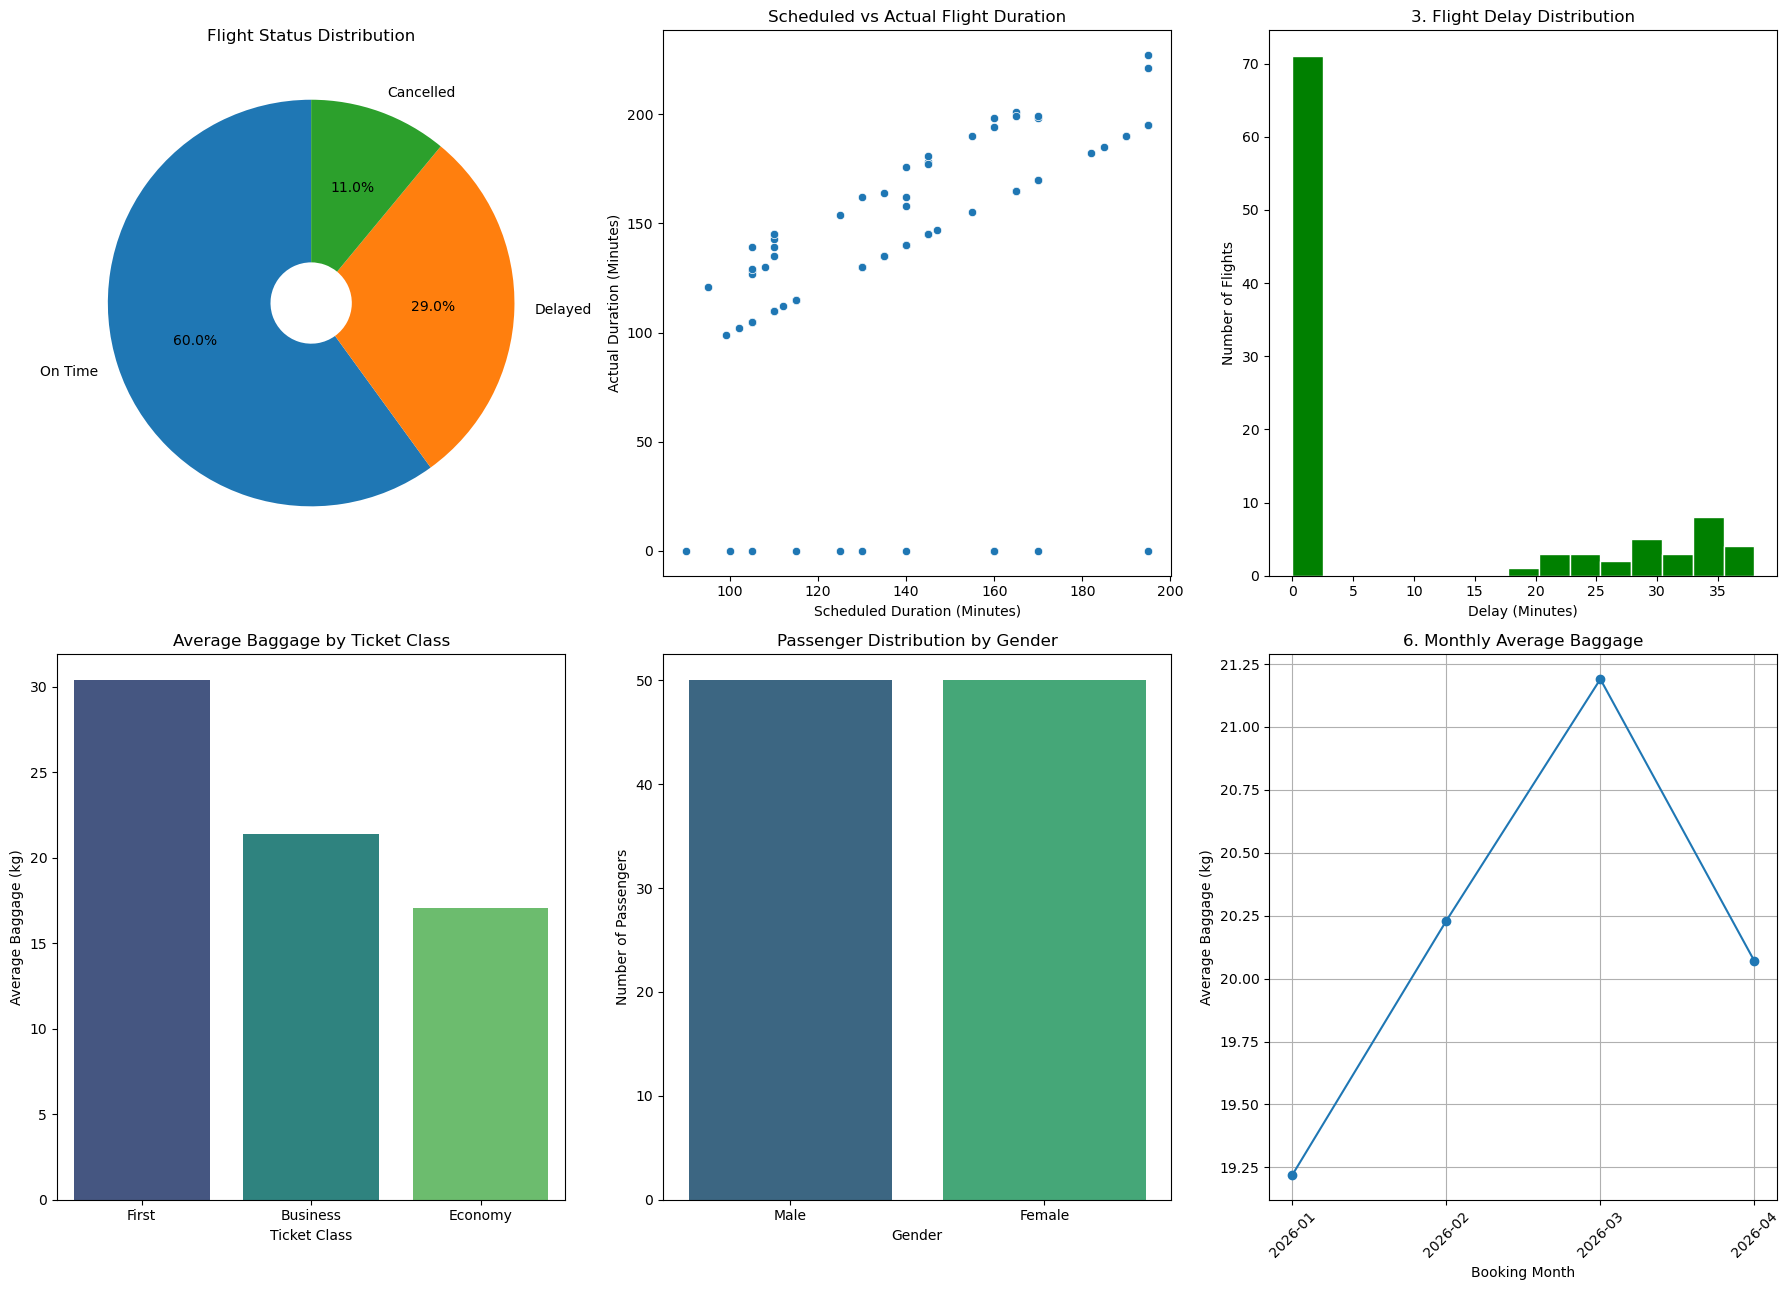

In [30]:
                                 #Flight Operations & Passenger Behavior

fig,axes=plt.subplots(2,3,figsize=(18,13))
query1 = """SELECT status,COUNT(*) AS total_flights FROM flights GROUP BY status ORDER BY total_flights DESC;"""
df1 = pd.read_sql(query1, conn)
axes[0,0].pie(df1["total_flights"],labels=df1["status"],autopct="%1.1f%%",startangle=90,wedgeprops={"width": 0.8})
axes[0,0].set_title("Flight Status Distribution")

query2 = """SELECT flight_id,scheduled_duration,actual_duration FROM flights 
WHERE scheduled_duration IS NOT NULL AND actual_duration IS NOT NULL;"""
df2 = pd.read_sql(query2, conn)
sns.scatterplot(data=df2,x="scheduled_duration",y="actual_duration",ax=axes[0,1])
axes[0,1].set_title("Scheduled vs Actual Flight Duration")
axes[0,1].set_xlabel("Scheduled Duration (Minutes)")
axes[0,1].set_ylabel("Actual Duration (Minutes)")
plt.tight_layout()

query3 = """SELECT delay_minutes FROM flights WHERE delay_minutes IS NOT NULL;"""
df3 = pd.read_sql(query3, conn)
axes[0,2].hist(df3["delay_minutes"],bins=15,color="green",edgecolor="white")
axes[0,2].set_title("3. Flight Delay Distribution")
axes[0,2].set_xlabel("Delay (Minutes)")
axes[0,2].set_ylabel("Number of Flights")
plt.tight_layout()

query4 = """SELECT ticket_class,ROUND(AVG(baggage_kg), 2) AS average_baggage FROM passengers 
            WHERE baggage_kg IS NOT NULL GROUP BY ticket_class ORDER BY average_baggage DESC;"""
df4 = pd.read_sql(query4, conn)
sns.barplot(data=df4,x="ticket_class",y="average_baggage",ax=axes[1,0],palette="viridis")
axes[1,0].set_title("Average Baggage by Ticket Class")
axes[1,0].set_xlabel("Ticket Class")
axes[1,0].set_ylabel("Average Baggage (kg)")
plt.tight_layout()

query5 = """SELECT gender,COUNT(*) AS passenger_count FROM passengers GROUP BY gender ORDER BY passenger_count DESC;"""
df5 = pd.read_sql(query5, conn)
sns.barplot(data=df5,x="gender",y="passenger_count",ax=axes[1,1],palette="viridis")
axes[1,1].set_title("Passenger Distribution by Gender")
axes[1,1].set_xlabel("Gender")
axes[1,1].set_ylabel("Number of Passengers")
plt.tight_layout()

query6 = """SELECT DATE_FORMAT(booking_date, '%Y-%m') AS booking_month,ROUND(AVG(baggage_kg), 2) AS average_baggage FROM passengers
            WHERE baggage_kg IS NOT NULL GROUP BY DATE_FORMAT(booking_date, '%Y-%m')ORDER BY booking_month;"""

df6 = pd.read_sql(query6, conn)
axes[1,2].plot(df6["booking_month"],df6["average_baggage"],marker="o")
axes[1,2].set_title("6. Monthly Average Baggage")
axes[1,2].set_xlabel("Booking Month")
axes[1,2].set_ylabel("Average Baggage (kg)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()


plt.show()


